# EfficientViT on the Chest CT-Scan Images dataset (lung cancer, 4 classes)

Implementation of **EfficientViT: Memory Efficient Vision Transformer with Cascaded Group Attention** (Liu et al., CVPR 2023) in PyTorch, trained **from scratch**.

What is implemented (Fig. 6 and Table 1 of the paper):
- **Overlapping patch embedding** (four stride-2 convs = 16x16 patches)
- **Sandwich-layout block** (Eq. 1): DWConv token interaction + FFN -> **one** self-attention layer -> DWConv + FFN. FFN expansion ratio 2, BatchNorm, ReLU
- **Cascaded Group Attention** (Eq. 2-3): each head gets a different channel split; head j adds the output of head j-1 to its input; token-interaction DWConv after the Q projection; Q/K dim 16, V dim = channels per head (parameter reallocation)
- **EfficientViT subsample block** (inverted residual with SE instead of attention)
- Variants **M0-M5** from Table 1 (choose with `VARIANT`)

**Fidelity notes.** The paper does not list per-head DWConv kernel sizes, the attention window size, or the relative-position bias; I follow the official code's choices (kernels 5/7/3, window 7, learned relative bias). I wrote this from the paper and my memory of the official code, so small details may differ from the released code.

Outputs: train / val / test loss, accuracy, F1, precision, recall curves; confusion matrices; classification report; ROC; parameters and forward/backward FLOPs.

In [1]:
!pip install -q kagglehub seaborn scikit-learn tqdm pillow

## 1. Config

In [2]:
import os, math, time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import classification_report

# ---------------- model ----------------
VARIANT      = "M2"      # M0 (smallest) ... M5 (largest), Table 1 of the paper
IMG_SIZE     = 224
# ---------------- training ----------------
BATCH_SIZE   = 32
EPOCHS       = 50
LR           = 1e-3      # paper: 1e-3 (AdamW)
WEIGHT_DECAY = 0.025     # paper: 2.5e-2
SEED         = 42

# ---------------- switches (all OFF = plain training) ----------------
USE_AUGMENTATION  = False   # small rotation / shift / scale + brightness-contrast (no flips)
USE_CLASS_WEIGHTS = False   # class-weighted cross-entropy

AVG = "macro"             # averaging for precision / recall / F1
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE = device
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

device: cuda | Tesla T4


## 2. Data

[Chest CT-Scan images Dataset (Kaggle, mohamedhanyyy)](https://www.kaggle.com/datasets/mohamedhanyyy/chest-ctscan-images): 2D CT slices in 4 classes (adenocarcinoma, large cell carcinoma, squamous cell carcinoma, normal) with ready-made train / valid / test folders. In a Kaggle notebook, add the dataset as input; elsewhere `kagglehub` needs your Kaggle API token.

In [3]:
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
# os.environ["KAGGLE_USERNAME"] = "your_username"   # only if you do not have ~/.kaggle/kaggle.json
# os.environ["KAGGLE_KEY"]      = "your_key"
KAGGLE_PATH = "/kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data"   # layout: Data/{train,valid,test}
if os.path.exists(KAGGLE_PATH):
    DATA_DIR = KAGGLE_PATH
else:                                   # other layout / not on Kaggle: search, or download with kagglehub
    root = "/kaggle/input"
    if not os.path.exists(root):
        import kagglehub
        root = kagglehub.dataset_download("mohamedhanyyy/chest-ctscan-images")
    DATA_DIR = next((dp for dp, dn, _ in os.walk(root, followlinks=True) if {"train", "valid", "test"} <= set(dn)), None)
    if DATA_DIR is None:
        for dp, dn, _ in os.walk(root, followlinks=True):           # show what is really there
            print(dp, dn[:6])
        raise FileNotFoundError("no folder with train/valid/test found under " + root)
print("DATA_DIR:", DATA_DIR)

CLASS_NAMES = ["adenocarcinoma", "large.cell.carcinoma", "normal", "squamous.cell.carcinoma"]; NUM_CLASSES = 4
def class_index(folder):      # folder names differ between splits (train/valid long names, test short names)
    for i, n in enumerate(CLASS_NAMES):
        if folder.lower().startswith(n): return i
    raise ValueError(folder)

def load_split(split):
    base = os.path.join(DATA_DIR, split); xs, ys = [], []
    items = [(os.path.join(base, d, f), class_index(d)) for d in sorted(os.listdir(base)) for f in sorted(os.listdir(os.path.join(base, d)))
             if f.lower().endswith((".png", ".jpg", ".jpeg"))]
    def one(p): return np.asarray(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)
    with ThreadPoolExecutor(8) as ex: xs = list(tqdm(ex.map(one, [p for p, _ in items]), total=len(items), desc=split))
    return np.stack(xs), np.array([y for _, y in items])

Xtr, Ytr = load_split("train"); Xva, Yva = load_split("valid"); Xte, Yte = load_split("test")
print(Xtr.shape, Xva.shape, Xte.shape)
for n, y in [("train", Ytr), ("val", Yva), ("test", Yte)]:
    print(f"{n:5s}", dict(zip(CLASS_NAMES, np.bincount(y, minlength=4))))

DATA_DIR: /kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data


train:   0%|          | 0/613 [00:00<?, ?it/s]

valid:   0%|          | 0/72 [00:00<?, ?it/s]

test:   0%|          | 0/315 [00:00<?, ?it/s]

(613, 224, 224) (72, 224, 224) (315, 224, 224)
train {'adenocarcinoma': np.int64(195), 'large.cell.carcinoma': np.int64(115), 'normal': np.int64(148), 'squamous.cell.carcinoma': np.int64(155)}
val   {'adenocarcinoma': np.int64(23), 'large.cell.carcinoma': np.int64(21), 'normal': np.int64(13), 'squamous.cell.carcinoma': np.int64(15)}
test  {'adenocarcinoma': np.int64(120), 'large.cell.carcinoma': np.int64(51), 'normal': np.int64(54), 'squamous.cell.carcinoma': np.int64(90)}


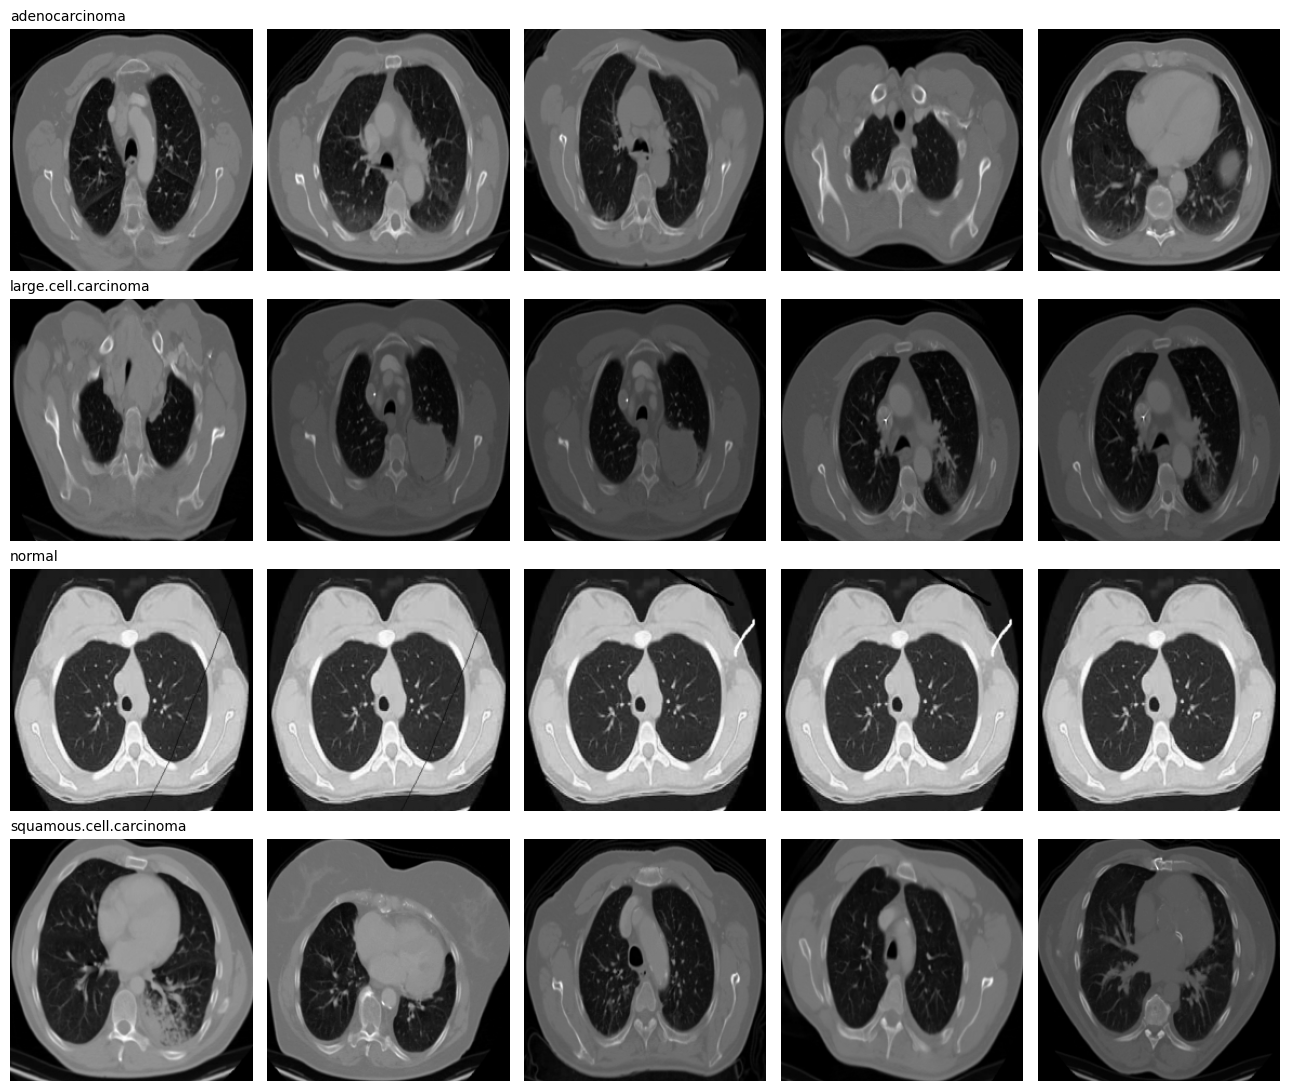

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(4, 5, figsize=(13, 11))
for cls in range(4):
    for a, i in zip(ax[cls], np.where(Ytr == cls)[0][:5]):
        a.imshow(Xtr[i], cmap="gray"); a.axis("off")
    ax[cls][0].set_title(CLASS_NAMES[cls], loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 3. EfficientViT model

In [5]:
import itertools, torch, torch.nn as nn, torch.nn.functional as F


class ConvBN(nn.Sequential):
    def __init__(self, a, b, ks=1, stride=1, pad=0, groups=1, bn_weight_init=1.0):
        super().__init__()
        self.add_module("c", nn.Conv2d(a, b, ks, stride, pad, groups=groups, bias=False))
        self.add_module("bn", nn.BatchNorm2d(b))
        nn.init.constant_(self.bn.weight, bn_weight_init)
        nn.init.constant_(self.bn.bias, 0)


class Residual(nn.Module):
    def __init__(self, m, drop=0.0):
        super().__init__()
        self.m, self.drop = m, drop

    def forward(self, x):
        if self.training and self.drop > 0:
            keep = torch.rand(x.size(0), 1, 1, 1, device=x.device).ge_(self.drop).div(1 - self.drop).detach()
            return x + self.m(x) * keep
        return x + self.m(x)


class FFN(nn.Module):
    """Memory-efficient FFN of the sandwich layout (expansion ratio 2, ReLU, BatchNorm)."""
    def __init__(self, dim, hidden):
        super().__init__()
        self.pw1 = ConvBN(dim, hidden)
        self.act = nn.ReLU()
        self.pw2 = ConvBN(hidden, dim, bn_weight_init=0.0)

    def forward(self, x):
        return self.pw2(self.act(self.pw1(x)))


class SqueezeExcite(nn.Module):
    def __init__(self, c, rd=0.25):
        super().__init__()
        r = max(1, int(c * rd))
        self.fc1, self.fc2 = nn.Conv2d(c, r, 1), nn.Conv2d(r, c, 1)

    def forward(self, x):
        s = x.mean((2, 3), keepdim=True)
        return x * torch.sigmoid(self.fc2(F.relu(self.fc1(s))))


class PatchMerging(nn.Module):
    """EfficientViT subsample: inverted residual (1x1 -> 3x3 dw stride 2 -> SE -> 1x1)."""
    def __init__(self, dim, out_dim):
        super().__init__()
        hid = int(dim * 4)
        self.conv1 = ConvBN(dim, hid, 1)
        self.act = nn.ReLU()
        self.conv2 = ConvBN(hid, hid, 3, 2, 1, groups=hid)
        self.se = SqueezeExcite(hid, 0.25)
        self.conv3 = ConvBN(hid, out_dim, 1)

    def forward(self, x):
        x = self.act(self.conv1(x))
        x = self.act(self.conv2(x))
        return self.conv3(self.se(x))


class CascadedGroupAttention(nn.Module):
    """Eq. (2)+(3): each head gets a different split of the channels; head j adds the output of head j-1 to its input.
    A token-interaction depthwise conv is applied to Q (Fig. 6c). Learned relative-position attention bias."""
    def __init__(self, dim, key_dim, num_heads, resolution, kernels):
        super().__init__()
        assert dim % num_heads == 0
        self.nh, self.key_dim, self.scale = num_heads, key_dim, key_dim ** -0.5
        self.d = dim // num_heads                       # V dimension = input split (V ratio ~1.0 w.r.t. embedding)
        self.qkvs = nn.ModuleList([ConvBN(dim // num_heads, key_dim * 2 + self.d) for _ in range(num_heads)])
        self.dws = nn.ModuleList([ConvBN(key_dim, key_dim, kernels[i % len(kernels)], 1,
                                         kernels[i % len(kernels)] // 2, groups=key_dim) for i in range(num_heads)])
        self.proj = nn.Sequential(nn.ReLU(), ConvBN(self.d * num_heads, dim, bn_weight_init=0.0))
        pts = list(itertools.product(range(resolution), range(resolution)))
        offs, idxs = {}, []
        for p1 in pts:
            for p2 in pts:
                o = (abs(p1[0] - p2[0]), abs(p1[1] - p2[1]))
                offs.setdefault(o, len(offs)); idxs.append(offs[o])
        self.attention_biases = nn.Parameter(torch.zeros(num_heads, len(offs)))
        self.register_buffer("bias_idxs", torch.LongTensor(idxs).view(len(pts), len(pts)), persistent=False)

    def forward(self, x):
        B, C, H, W = x.shape
        bias = self.attention_biases[:, self.bias_idxs]
        splits = x.chunk(self.nh, dim=1)
        feat, outs = splits[0], []
        for i, qkv in enumerate(self.qkvs):
            if i > 0:
                feat = feat + splits[i]                 # cascade: add previous head output (Eq. 3)
            feat = qkv(feat)
            q, k, v = feat.view(B, -1, H, W).split([self.key_dim, self.key_dim, self.d], dim=1)
            q = self.dws[i](q)                          # token interaction after the Q projection
            q, k, v = q.flatten(2), k.flatten(2), v.flatten(2)
            attn = ((q.transpose(-2, -1) @ k) * self.scale + bias[i]).softmax(-1)
            feat = (v @ attn.transpose(-2, -1)).reshape(B, self.d, H, W)
            outs.append(feat)
        return self.proj(torch.cat(outs, 1))


class LocalWindowAttention(nn.Module):
    """CGA applied inside non-overlapping windows (window 7 as in the official implementation)."""
    def __init__(self, dim, key_dim, num_heads, resolution, kernels, window=7):
        super().__init__()
        self.ws = min(window, resolution)
        self.attn = CascadedGroupAttention(dim, key_dim, num_heads, self.ws, kernels)

    def forward(self, x):
        B, C, H, W = x.shape
        ws = self.ws
        if H <= ws and W <= ws:
            return self.attn(x)
        x = x.permute(0, 2, 3, 1)
        pb, pr = (ws - H % ws) % ws, (ws - W % ws) % ws
        if pb or pr:
            x = F.pad(x, (0, 0, 0, pr, 0, pb))
        pH, pW = H + pb, W + pr
        nH, nW = pH // ws, pW // ws
        x = x.view(B, nH, ws, nW, ws, C).transpose(2, 3).reshape(B * nH * nW, ws, ws, C).permute(0, 3, 1, 2)
        x = self.attn(x)
        x = x.permute(0, 2, 3, 1).view(B, nH, nW, ws, ws, C).transpose(2, 3).reshape(B, pH, pW, C)
        if pb or pr:
            x = x[:, :H, :W].contiguous()
        return x.permute(0, 3, 1, 2)


class EfficientViTBlock(nn.Module):
    """Sandwich layout (Eq. 1, N=1): [DWConv token interaction -> FFN] -> CGA -> [DWConv -> FFN]."""
    def __init__(self, dim, key_dim, num_heads, resolution, kernels, window=7, drop=0.0):
        super().__init__()
        self.dw0 = Residual(ConvBN(dim, dim, 3, 1, 1, groups=dim, bn_weight_init=0.0))
        self.ffn0 = Residual(FFN(dim, dim * 2))
        self.mixer = Residual(LocalWindowAttention(dim, key_dim, num_heads, resolution, kernels, window), drop)
        self.dw1 = Residual(ConvBN(dim, dim, 3, 1, 1, groups=dim, bn_weight_init=0.0))
        self.ffn1 = Residual(FFN(dim, dim * 2))

    def forward(self, x):
        return self.ffn1(self.dw1(self.mixer(self.ffn0(self.dw0(x)))))


# Table 1 of the paper: {C1,C2,C3}, {L1,L2,L3}, {H1,H2,H3}. The per-head depthwise kernel sizes are not listed in the
# paper; they follow the official code.
VARIANTS = {
    "M0": dict(embed_dim=[64, 128, 192],  depth=[1, 2, 3], num_heads=[4, 4, 4], kernels=[5, 5, 5, 5]),
    "M1": dict(embed_dim=[128, 144, 192], depth=[1, 2, 3], num_heads=[2, 3, 3], kernels=[7, 5, 3, 3]),
    "M2": dict(embed_dim=[128, 192, 224], depth=[1, 2, 3], num_heads=[4, 3, 2], kernels=[7, 5, 3, 3]),
    "M3": dict(embed_dim=[128, 240, 320], depth=[1, 2, 3], num_heads=[4, 3, 4], kernels=[5, 5, 5, 5]),
    "M4": dict(embed_dim=[128, 256, 384], depth=[1, 2, 3], num_heads=[4, 4, 4], kernels=[7, 5, 3, 3]),
    "M5": dict(embed_dim=[192, 288, 384], depth=[1, 3, 4], num_heads=[3, 3, 4], kernels=[7, 5, 3, 3]),
}


class EfficientViT(nn.Module):
    def __init__(self, variant="M2", in_chans=1, num_classes=2, img_size=224, key_dim=16, window=7,
                 drop_path=0.0, head_dropout=0.0):
        super().__init__()
        cfg = VARIANTS[variant]
        ed, dep, nh, ks = cfg["embed_dim"], cfg["depth"], cfg["num_heads"], cfg["kernels"]
        # overlapping patch embedding: 4 stride-2 convs = 16x16 patches -> tokens of dim C1
        self.patch_embed = nn.Sequential(
            ConvBN(in_chans, ed[0] // 8, 3, 2, 1), nn.ReLU(),
            ConvBN(ed[0] // 8, ed[0] // 4, 3, 2, 1), nn.ReLU(),
            ConvBN(ed[0] // 4, ed[0] // 2, 3, 2, 1), nn.ReLU(),
            ConvBN(ed[0] // 2, ed[0], 3, 2, 1))
        res = img_size
        for _ in range(4):
            res = (res - 1) // 2 + 1
        layers = []
        for i in range(3):
            for _ in range(dep[i]):
                layers.append(EfficientViTBlock(ed[i], key_dim, nh[i], res, ks, window, drop_path))
            if i < 2:   # EfficientViT subsample block (sandwich layout, attention replaced by inverted residual)
                nxt = ed[i + 1]
                layers += [Residual(ConvBN(ed[i], ed[i], 3, 1, 1, groups=ed[i])), Residual(FFN(ed[i], ed[i] * 2)),
                           PatchMerging(ed[i], nxt),
                           Residual(ConvBN(nxt, nxt, 3, 1, 1, groups=nxt)), Residual(FFN(nxt, nxt * 2))]
                res = (res - 1) // 2 + 1
        self.blocks = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.BatchNorm1d(ed[-1]), nn.Dropout(head_dropout), nn.Linear(ed[-1], num_classes))
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.blocks(self.patch_embed(x))
        return self.head(x.mean((2, 3)))

## 4. Training utilities

In [6]:
import math, time, copy, random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, roc_auc_score


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


class ArrayLoader:
    """Serves batches from an in-memory uint8 array (N,H,W). No dataloader workers, no disk reads."""
    def __init__(self, X, Y, bs, shuffle=False, augment=False, drop_last=False):
        self.X = torch.from_numpy(np.ascontiguousarray(X)).unsqueeze(1)
        self.Y = torch.from_numpy(np.asarray(Y)).long()
        self.bs, self.shuffle, self.augment, self.drop_last = bs, shuffle, augment, drop_last

    def __len__(self):
        n = len(self.X)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def _aug(self, x):   # rotation +-10 deg, translation +-5%, scale 0.95-1.05, brightness/contrast. No flips.
        B, d = x.shape[0], x.device
        ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(10)
        s = 1 + (torch.rand(B, device=d) * 2 - 1) * 0.05
        tx, ty = [(torch.rand(B, device=d) * 2 - 1) * 0.1 for _ in range(2)]
        c, si = torch.cos(ang) * s, torch.sin(ang) * s
        theta = torch.stack([torch.stack([c, -si, tx], 1), torch.stack([si, c, ty], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
        br = torch.rand(B, 1, 1, 1, device=d) * 0.4 - 0.2
        ct = torch.rand(B, 1, 1, 1, device=d) * 0.4 + 0.8
        m = x.mean((1, 2, 3), keepdim=True)
        return ((x - m) * ct + m + br).clamp(0, 1)

    def __iter__(self):
        dev = DEVICE
        idx = torch.randperm(len(self.X)) if self.shuffle else torch.arange(len(self.X))
        for i in range(len(self)):
            b = idx[i * self.bs:(i + 1) * self.bs]
            x = self.X[b].to(dev, non_blocking=True).float().div_(255)
            if self.augment:
                x = self._aug(x)
            yield (x - 0.5) / 0.5, self.Y[b].to(dev, non_blocking=True)


def metrics(y, p, avg):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average=avg, pos_label=1, zero_division=0)
    return dict(acc=accuracy_score(y, p), precision=pr, recall=rc, f1=f1)


def auc_score(y, prob):
    try:
        if prob.shape[1] == 2:
            return roc_auc_score(y, prob[:, 1])
        return roc_auc_score(y, prob, multi_class="ovr", average="macro")
    except ValueError:
        return float("nan")


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    tot, n, ys, ps, pr = 0.0, 0, [], [], []
    for x, y in loader:
        out = model(x).float()
        tot += criterion(out, y).item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu()); pr.append(out.softmax(1).cpu())
    return tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(pr).numpy()


def fit(model, train_loader, val_loader, test_loader, criterion, device, avg, epochs=30, lr=1e-3,
        weight_decay=0.025, warmup=3, use_amp=True, ckpt="best_efficientvit.pt"):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: (e + 1) / warmup if e < warmup
                                              else 0.5 * (1 + math.cos(math.pi * (e - warmup) / max(1, epochs - warmup))))
    use_amp = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    keys = ["loss", "acc", "f1", "precision", "recall"]
    hist = {f"{s}_{k}": [] for s in ["train", "val", "test"] for k in keys}
    hist["lr"] = []
    best_f1, best_state = -1.0, None
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train()
        tot, n, ys, ps = 0.0, 0, [], []
        for x, y in train_loader:
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
            loss = criterion(out.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update()
            tot += loss.item() * x.size(0); n += x.size(0)
            ys.append(y.cpu()); ps.append(out.argmax(1).detach().cpu())
        tr = (tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy())
        vl, vy, vp, _ = evaluate(model, val_loader, criterion)
        sl, sy, sp, _ = evaluate(model, test_loader, criterion)          # monitoring only, never used for selection
        for name, (l, y, p) in [("train", tr), ("val", (vl, vy, vp)), ("test", (sl, sy, sp))]:
            hist[f"{name}_loss"].append(l)
            for k, v in metrics(y, p, avg).items():
                hist[f"{name}_{k}"].append(v)
        hist["lr"].append(opt.param_groups[0]["lr"]); sched.step()
        improved = hist["val_f1"][-1] > best_f1
        if improved:
            best_f1 = hist["val_f1"][-1]; best_state = copy.deepcopy(model.state_dict()); torch.save(best_state, ckpt)
        print(f"Ep {ep:02d}/{epochs} | {time.time()-t0:5.1f}s | loss tr {tr[0]:.4f} val {vl:.4f} test {sl:.4f} | "
              f"F1 tr {hist['train_f1'][-1]:.3f} val {hist['val_f1'][-1]:.3f} test {hist['test_f1'][-1]:.3f}"
              + ("  *best*" if improved else ""))
    model.load_state_dict(best_state)
    return hist

In [7]:
set_seed(SEED)
cw = None
if USE_CLASS_WEIGHTS:
    cnt = np.bincount(Ytr, minlength=NUM_CLASSES); cw = torch.tensor(cnt.sum() / (NUM_CLASSES * cnt), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=cw)

train_loader = ArrayLoader(Xtr, Ytr, BATCH_SIZE, shuffle=True, augment=USE_AUGMENTATION, drop_last=True)
val_loader   = ArrayLoader(Xva, Yva, BATCH_SIZE * 2)
test_loader  = ArrayLoader(Xte, Yte, BATCH_SIZE * 2)

model = EfficientViT(VARIANT, in_chans=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE).to(device)
print("output shape:", model(torch.randn(2, 1, IMG_SIZE, IMG_SIZE, device=device)).shape)

output shape: torch.Size([2, 4])


## 5. Parameters and FLOPs (forward / backward, per image and per batch)

In [8]:
import pandas as pd
from torch.utils.flop_counter import FlopCounterMode

def measure_flops(model, batch_size):
    """Forward and backward FLOPs of one training step (1 multiply-add = 2 FLOPs; matmul/conv/attention only)."""
    model.train(); model.zero_grad(set_to_none=True)
    x = torch.randn(batch_size, 1, IMG_SIZE, IMG_SIZE, device=device)
    with FlopCounterMode(display=False) as fc:
        out = model(x); fwd = fc.get_total_flops()
        out.float().sum().backward(); tot = fc.get_total_flops()
    model.zero_grad(set_to_none=True)
    return fwd, tot - fwd

def complexity_report(model):
    total = sum(p.numel() for p in model.parameters()); trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    fb, bb = measure_flops(model, BATCH_SIZE)
    f2, b2 = measure_flops(model, 2)               # per image = batch of 2 / 2 (BatchNorm needs >1 sample in train mode)
    f1, b1 = f2 / 2, b2 / 2
    fmt = lambda v: f"{v/1e6:.2f} M" if v < 1e9 else f"{v/1e9:.3f} G"
    rows = {"Total parameters": total, "Trainable parameters": trainable, "Non-trainable parameters": total - trainable,
            "Forward FLOPs / image": f1, "Backward FLOPs / image": b1, "Forward+Backward FLOPs / image": f1 + b1,
            f"Forward FLOPs / batch ({BATCH_SIZE})": fb, f"Backward FLOPs / batch ({BATCH_SIZE})": bb,
            f"Forward+Backward FLOPs / batch ({BATCH_SIZE})": fb + bb, "Forward MAdds / image (FLOPs/2, paper unit)": f1 / 2}
    df = pd.DataFrame({"value": rows}); df["readable"] = [fmt(v) for v in df["value"]]
    print(f"Input 1 x {IMG_SIZE} x {IMG_SIZE} | batch {BATCH_SIZE}"); display(df); df.to_csv("model_complexity.csv")

complexity_report(model)

Input 1 x 224 x 224 | batch 32


,value,readable
Total parameters,3.963166e+06,3.96 M
Trainable parameters,3.963166e+06,3.96 M
Non-trainable parameters,0.000000e+00,0.00 M
Forward FLOPs / image,3.943999e+08,394.40 M
Backward FLOPs / image,1.666684e+09,1.667 G
Forward+Backward FLOPs / image,2.061084e+09,2.061 G
Forward FLOPs / batch (32),1.262080e+10,12.621 G
Backward FLOPs / batch (32),5.333390e+10,53.334 G
Forward+Backward FLOPs / batch (32),6.595469e+10,65.955 G
"Forward MAdds / image (FLOPs/2, paper unit)",1.971999e+08,197.20 M


## 6. Training

AdamW, linear warm-up + cosine decay, mixed precision on GPU. Test metrics are logged each epoch **only** for the curves; the best checkpoint is chosen by **validation F1**.

In [9]:
set_seed(SEED)
model = EfficientViT(VARIANT, in_chans=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE).to(device)
history = fit(model, train_loader, val_loader, test_loader, criterion, device, AVG,
              epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY, ckpt="best_efficientvit.pt")

Ep 01/50 |   4.1s | loss tr 0.9068 val 1.4534 test 1.4010 | F1 tr 0.584 val 0.086 test 0.111  *best*
Ep 02/50 |   1.5s | loss tr 0.3604 val 2.4036 test 1.9655 | F1 tr 0.906 val 0.087 test 0.115  *best*
Ep 03/50 |   1.5s | loss tr 0.1123 val 1.2850 test 1.5249 | F1 tr 0.983 val 0.635 test 0.450  *best*
Ep 04/50 |   1.5s | loss tr 0.1026 val 1.0259 test 2.6658 | F1 tr 0.979 val 0.642 test 0.298  *best*
Ep 05/50 |   1.4s | loss tr 0.0839 val 1.1849 test 1.3649 | F1 tr 0.986 val 0.638 test 0.589
Ep 06/50 |   1.5s | loss tr 0.0629 val 0.9294 test 1.4931 | F1 tr 0.984 val 0.727 test 0.525  *best*
Ep 07/50 |   1.4s | loss tr 0.0827 val 0.8207 test 1.4743 | F1 tr 0.977 val 0.708 test 0.528
Ep 08/50 |   1.5s | loss tr 0.0466 val 0.8335 test 1.3709 | F1 tr 0.989 val 0.747 test 0.548  *best*
Ep 09/50 |   1.5s | loss tr 0.0326 val 1.0884 test 1.1850 | F1 tr 0.995 val 0.666 test 0.580
Ep 10/50 |   1.4s | loss tr 0.0427 val 1.1557 test 1.6158 | F1 tr 0.991 val 0.675 test 0.502
Ep 11/50 |   1.4s | lo

## 7. Curves

In [10]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc as sk_auc
from sklearn.preprocessing import label_binarize

def plot_history(h, avg_name):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(2, 3, figsize=(18, 9)); ax = ax.ravel()
    for a, (k, t) in zip(ax, [("loss", "Loss"), ("acc", "Accuracy"), ("f1", f"F1 ({avg_name})"),
                              ("precision", f"Precision ({avg_name})"), ("recall", f"Recall ({avg_name})")]):
        for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
            a.plot(ep, h[f"{s}_{k}"], label=s, color=c, lw=2)
        a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    ax[5].plot(ep, h["lr"], color="tab:red", lw=2); ax[5].set_title("Learning rate"); ax[5].set_xlabel("epoch"); ax[5].grid(alpha=.3)
    plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

def plot_loss_only(h):
    ep = range(1, len(h["train_loss"]) + 1)
    plt.figure(figsize=(8, 5))
    for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
        plt.plot(ep, h[f"{s}_loss"], label=f"{s} loss", color=c, lw=2)
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Train / Val / Test loss"); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

def plot_confusion(y, p, names, title, fname):
    n = len(names); cm = confusion_matrix(y, p, labels=range(n)); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    w = max(11, 1.6 * n * 2)
    fig, ax = plt.subplots(1, 2, figsize=(w, max(4.5, 0.9 * n + 2.5)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[0]); ax[0].set_title(f"{title} - counts")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[1], vmin=0, vmax=1)
    ax[1].set_title(f"{title} - normalised by true class")
    for a in ax:
        a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

def plot_roc(y, prob, names, fname="roc_curves.png"):
    plt.figure(figsize=(6.5, 5.5))
    if len(names) == 2:
        fpr, tpr, _ = roc_curve(y, prob[:, 1]); plt.plot(fpr, tpr, lw=2, label=f"{names[1]} (AUC {sk_auc(fpr, tpr):.3f})")
    else:
        yb = label_binarize(y, classes=range(len(names)))
        for i, n in enumerate(names):
            fpr, tpr, _ = roc_curve(yb[:, i], prob[:, i]); plt.plot(fpr, tpr, lw=2, label=f"{n} (AUC {sk_auc(fpr, tpr):.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=.5); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title("ROC (test)"); plt.legend(loc="lower right", fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(fname, dpi=150); plt.show()

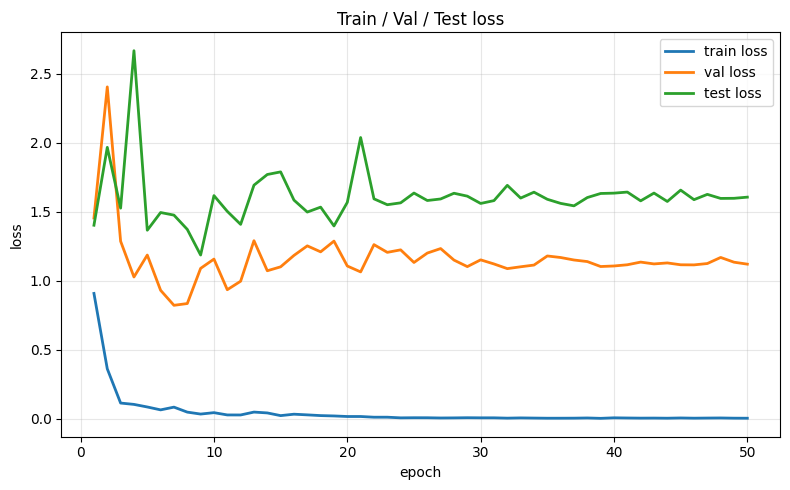

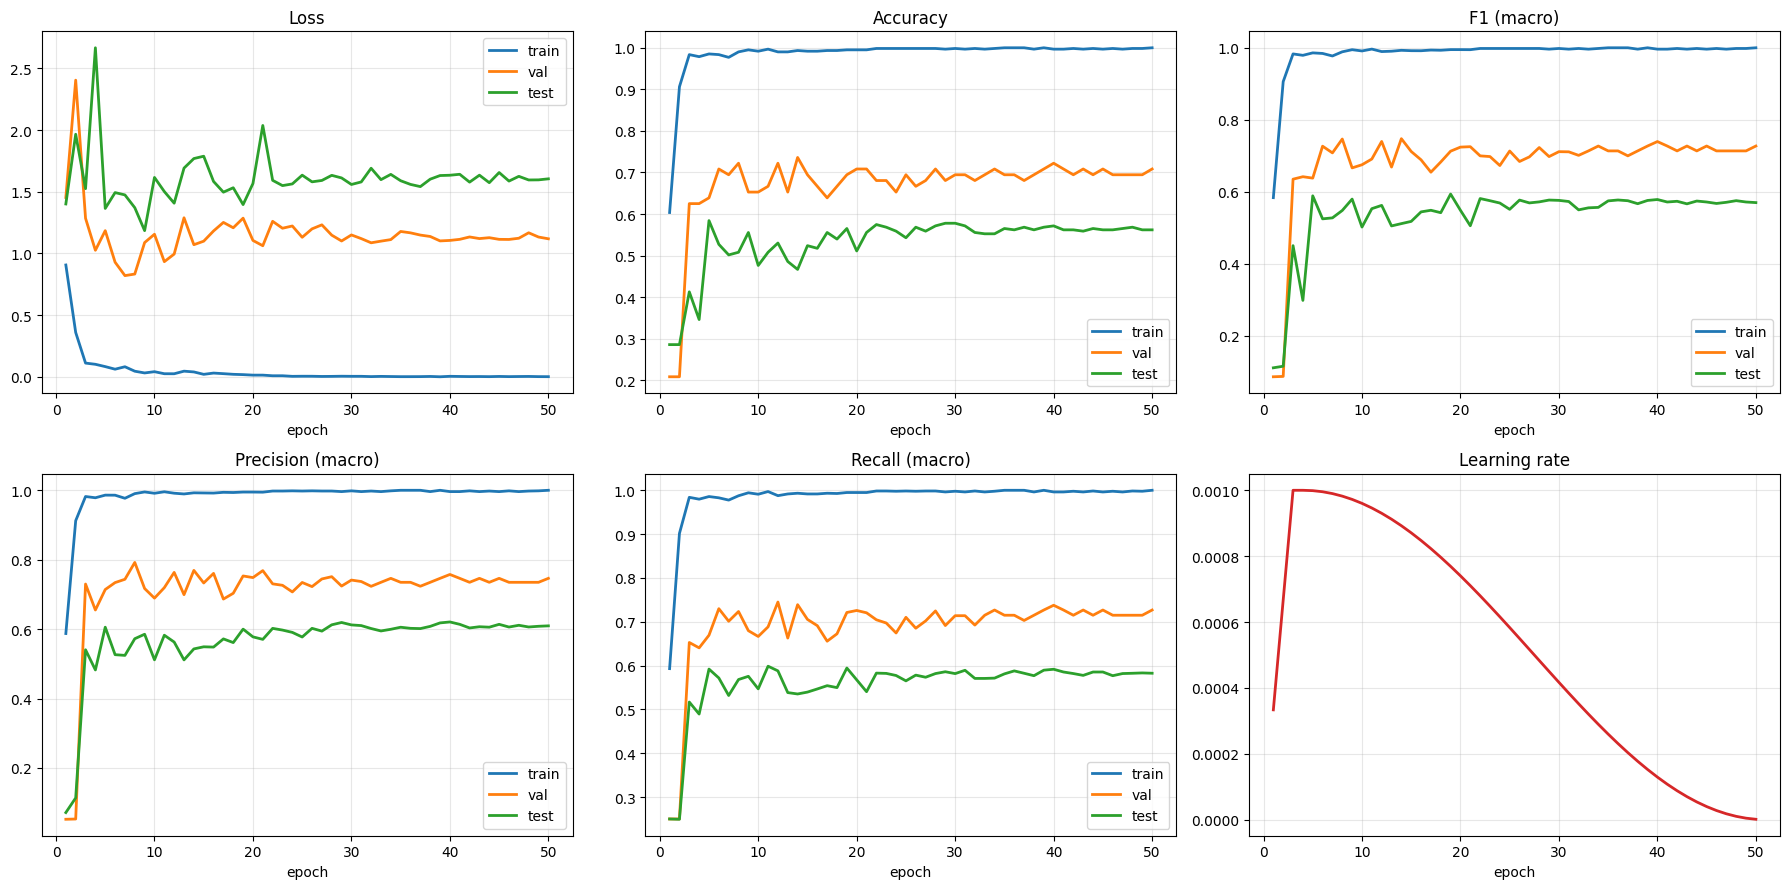

In [11]:
plot_loss_only(history)
plot_history(history, AVG)

## 8. Final evaluation (best-validation checkpoint)

In [12]:
import pandas as pd
res = {n: evaluate(model, l, criterion) for n, l in [("val", val_loader), ("test", test_loader)]}
rows = []
for n, (loss, y, p, prob) in res.items():
    m = metrics(y, p, AVG); m["loss"] = loss; m["auc"] = auc_score(y, prob); rows.append(pd.Series(m, name=n))
print(f"precision / recall / F1 = {AVG}-averaged")
print(pd.DataFrame(rows)[["loss", "acc", "precision", "recall", "f1", "auc"]].round(4))
_, ytest, ptest, probtest = res["test"]
print("\nTest classification report")
print(classification_report(ytest, ptest, target_names=CLASS_NAMES, digits=4, zero_division=0))

precision / recall / F1 = macro-averaged
        loss     acc  precision  recall      f1     auc
val   1.0711  0.7361     0.7692  0.7390  0.7475  0.8832
test  1.7687  0.4667     0.5429  0.5352  0.5116  0.7492

Test classification report
                         precision    recall  f1-score   support

         adenocarcinoma     0.4615    0.3500    0.3981       120
   large.cell.carcinoma     0.2377    0.5686    0.3353        51
                 normal     0.9623    0.9444    0.9533        54
squamous.cell.carcinoma     0.5102    0.2778    0.3597        90

               accuracy                         0.4667       315
              macro avg     0.5429    0.5352    0.5116       315
           weighted avg     0.5250    0.4667    0.4721       315



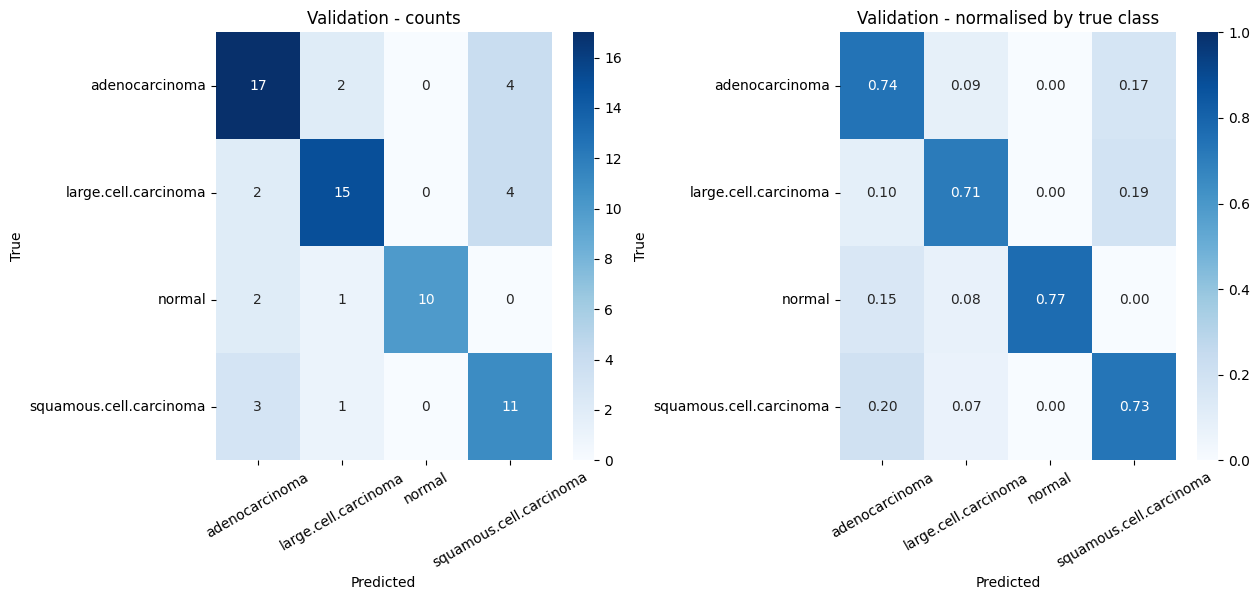

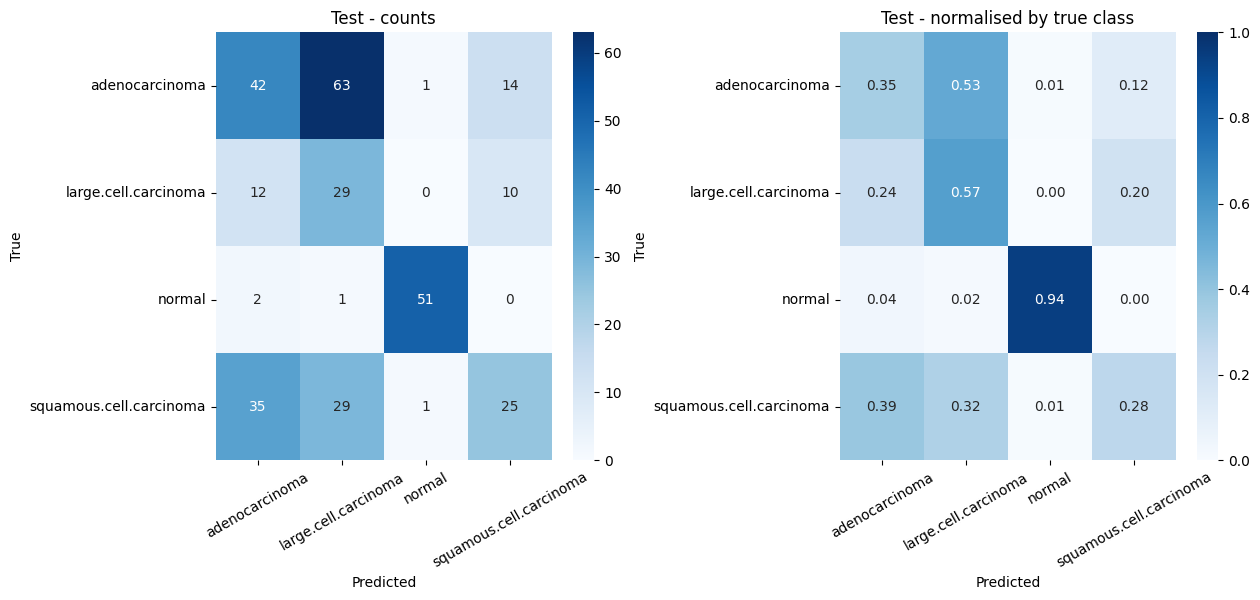

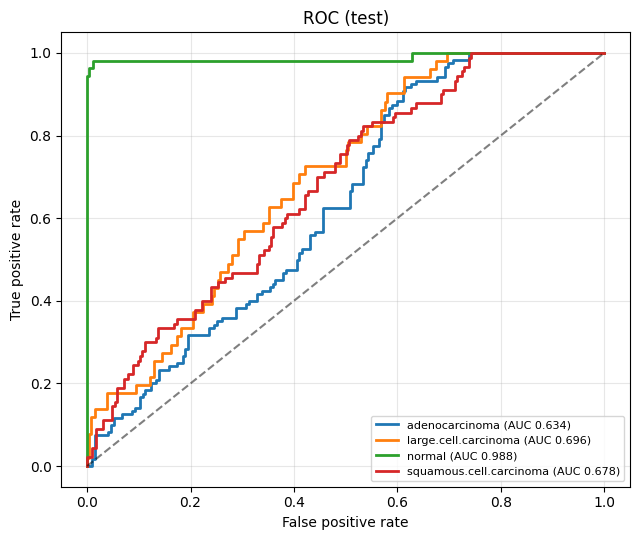

In [13]:
plot_confusion(res["val"][1], res["val"][2], CLASS_NAMES, "Validation", "confusion_val.png")
plot_confusion(ytest, ptest, CLASS_NAMES, "Test", "confusion_test.png")
plot_roc(ytest, probtest, CLASS_NAMES)

## Notes
- Plain training by default; set `USE_AUGMENTATION` / `USE_CLASS_WEIGHTS` at the top to change it.
- `VARIANT` M0-M5 selects the model size (Table 1). M2 is the default (about 4M parameters at 1000 classes).
- Images are decoded and resized once, kept in memory as uint8 and fed straight to the model, so there are no dataloader workers to crash.
- Best weights: `best_efficientvit.pt`; figures are saved as PNGs in the working directory.
- Only about 600 training images, so results move noticeably between seeds; consider several seeds and report mean +/- std.
- Precision / recall / F1 in the curves are **macro** averages over the 4 classes.